# Notebook 03: Single-Environment Diagnostics and Mixed Models

## Objective
Following data integration and QC (Notebooks 01-02), this notebook:
- Verifies the analysis-ready dataset
- Assesses trait missingness and experimental design connectivity
- Fits single-environment mixed models per trial
- Extracts and ranks per-trial BLUPs

Note: the pooled, combined multi-environment model (with proper G×E estimation)
is fit separately in R — see 04_combined_met_model.R

In [1]:
from pathlib import Path

PROJECT_DIR = Path.home() / "Potato_CET_MultiEnvironment"
DATA_DIR = PROJECT_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"
OUTPUT_DIR = PROJECT_DIR / "outputs"
FIGURES_DIR = OUTPUT_DIR / "figures"
TABLES_DIR = OUTPUT_DIR / "tables"

for folder in [OUTPUT_DIR, FIGURES_DIR, TABLES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_DIR}")
print(f"Processed dir exists: {PROCESSED_DIR.exists()}")

Project root: /home/nosin/Potato_CET_MultiEnvironment
Processed dir exists: True


In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

plt.rcParams["figure.dpi"] = 100

In [4]:
master = pd.read_csv(PROCESSED_DIR / "analysis_ready.csv")

print(f"Rows: {master.shape[0]:,}")
print(f"Columns: {master.shape[1]}")
master.head()

Rows: 1,314
Columns: 123


,plot,geno,entry,row,column,rep,ntp,npe,growth_speed,pgh,...,late_blight_70_days,late_blight_80_days,photo,selected,tubers_shape,selected_clones,calculated_total_count,calc_pct,yield_source,Genotype_Type
0,NaN,CIP3217004.022,10,1,1,1,20.0,20,5.0,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,193.0,5.699482,Original weight_g_total,Breeding Clone
1,NaN,CIP3177023.046,3,2,1,1,20.0,7,3.0,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,14.0,14.285714,Original weight_g_total,Breeding Clone
2,NaN,CIP3217016.038,47,3,1,1,20.0,15,5.0,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,52.0,9.615385,Original weight_g_total,Breeding Clone
3,NaN,CIP3217016.076,48,4,1,1,20.0,17,5.0,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,69.0,15.942029,Original weight_g_total,Breeding Clone
4,NaN,CIP3217006.008,20,5,1,1,20.0,16,7.0,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,149.0,4.026846,Original weight_g_total,Breeding Clone


verifying key variables

In [5]:
key_variables = ["trial", "geno", "rep", "row", "column", "weight_g_total"]

verification = pd.DataFrame({
    "Variable": key_variables,
    "Present": [col in master.columns for col in key_variables],
    "Missing Values": [master[col].isna().sum() for col in key_variables],
    "Data Type": [master[col].dtype for col in key_variables]
})
verification

,Variable,Present,Missing Values,Data Type
0,trial,True,0,str
1,geno,True,0,str
2,rep,True,0,int64
3,row,True,0,int64
4,column,True,0,int64
5,weight_g_total,True,13,float64


In [6]:
summary = pd.DataFrame({
    "Statistic": ["Trials", "Genotypes", "Replications", "Rows", "Columns", "Yield observations"],
    "Value": [
        master["trial"].nunique(),
        master["geno"].nunique(),
        master["rep"].nunique(),
        master["row"].nunique(),
        master["column"].nunique(),
        master["weight_g_total"].notna().sum()
    ]
})
summary

,Statistic,Value
0,Trials,6
1,Genotypes,189
2,Replications,1
3,Rows,44
4,Columns,11
5,Yield observations,1301


Trait missingness assessment

In [7]:
traits = ["weight_g_total", "dm", "late_blight_60_days", "late_blight_90_days", "nph", "ntp"]

missing_summary = (
    master[traits]
    .isna()
    .agg(["sum", "count"])
    .T
    .rename(columns={"sum": "Missing", "count": "Total"})
)
missing_summary["Available"] = missing_summary["Total"] - missing_summary["Missing"]
missing_summary["Percent Missing"] = 100 * missing_summary["Missing"] / missing_summary["Total"]
missing_summary

,Missing,Total,Available,Percent Missing
weight_g_total,13,1314,1301,0.989346
dm,1142,1314,172,86.910198
late_blight_60_days,615,1314,699,46.803653
late_blight_90_days,257,1314,1057,19.558600
nph,952,1314,362,72.450533
ntp,264,1314,1050,20.091324


missingness visualization

<Figure size 1200x600 with 0 Axes>

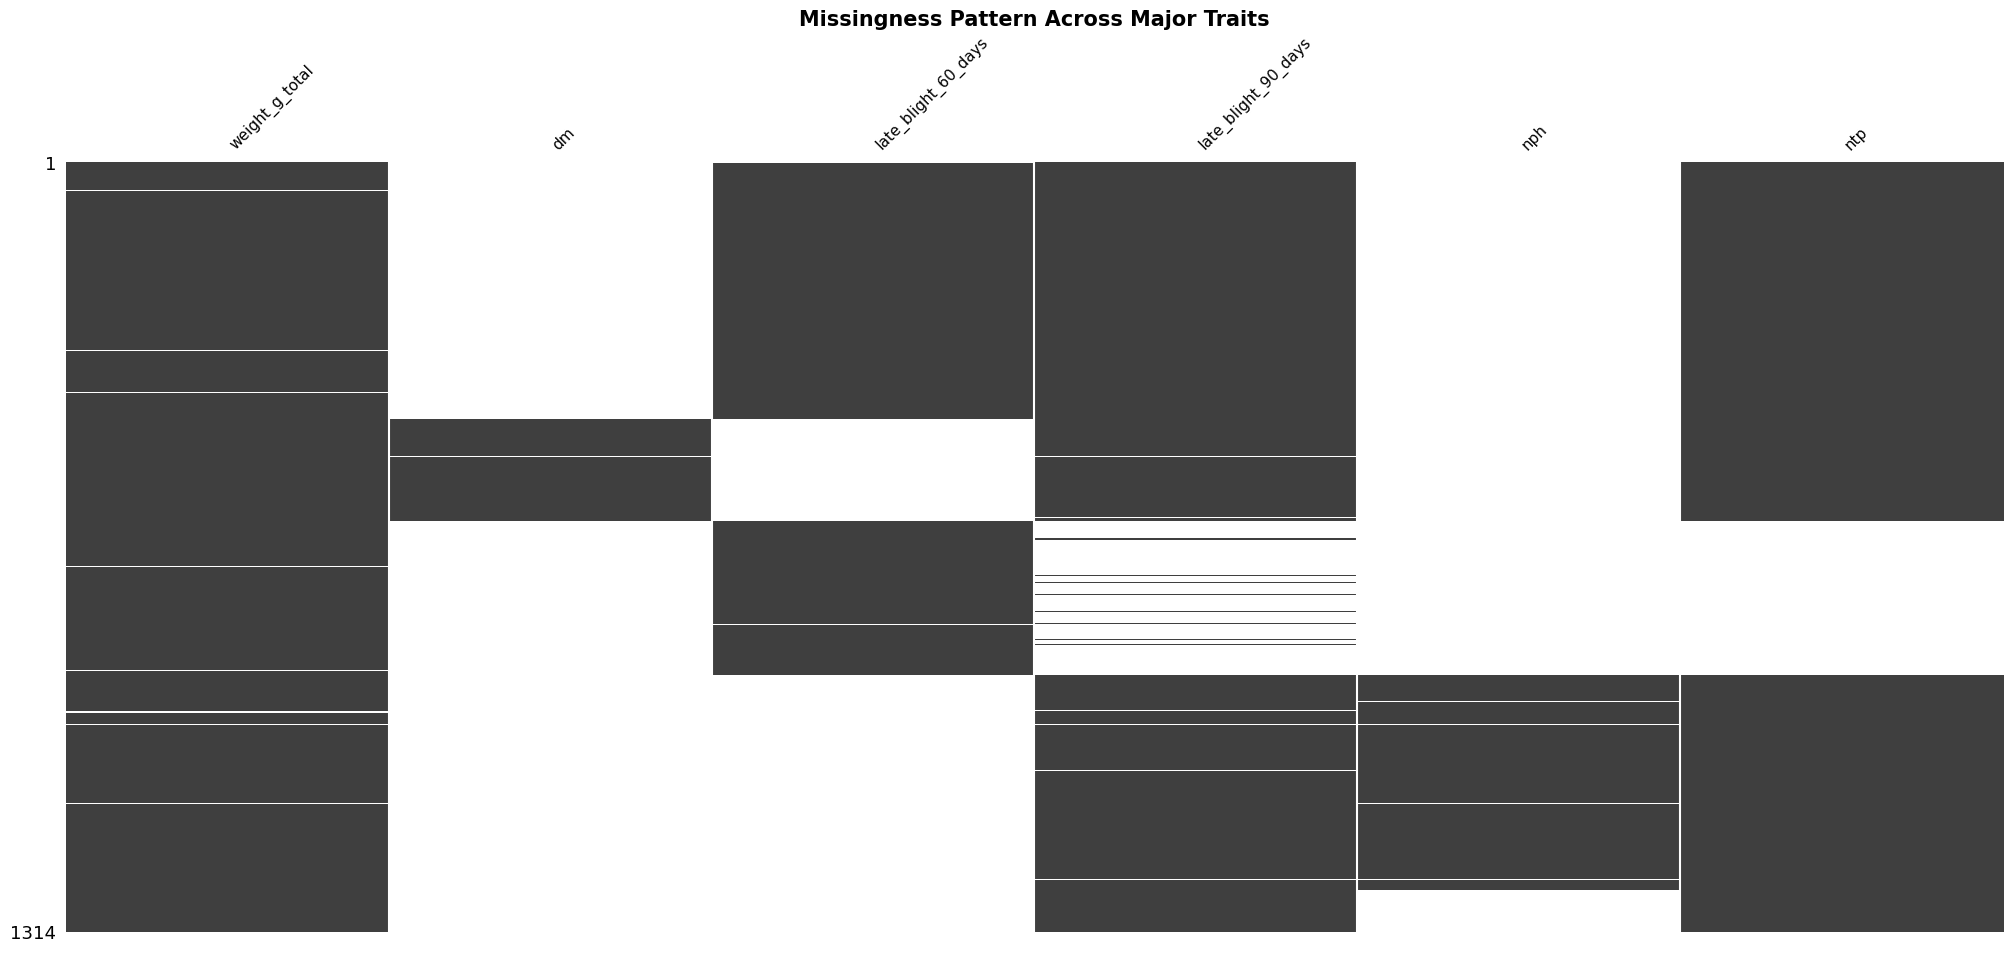

In [10]:
import missingno as msno

plt.figure(figsize=(12,6))
msno.matrix(master[traits], fontsize=11, sparkline=False)
plt.title("Missingness Pattern Across Major Traits", fontsize=15, weight="bold")
plt.savefig(FIGURES_DIR / "missingness_pattern_traits.png", dpi=300, bbox_inches="tight")
plt.show()

In [11]:
print("="*70)
print("EXPERIMENTAL DESIGN SUMMARY")
print("="*70)

summary = pd.DataFrame({
    "Metric": ["Total observations", "Genotypes", "Environments", "Rows", "Columns", "Replications"],
    "Value": [
        len(master),
        master["geno"].nunique(),
        master["trial"].nunique(),
        master["row"].nunique(),
        master["column"].nunique(),
        master["rep"].nunique()
    ]
})
summary

EXPERIMENTAL DESIGN SUMMARY


,Metric,Value
0,Total observations,1314
1,Genotypes,189
2,Environments,6
3,Rows,44
4,Columns,11
5,Replications,1


In [12]:
env_summary = (
    master
    .groupby(["trial","location","population"])
    .size()
    .reset_index(name="Plots")
    .sort_values("Plots", ascending=False)
)
env_summary

,trial,location,population,Plots
1,KE25MOL-LBHT-IT01_table-Final,Molo,LBHT,264
3,KE25NJO-LBHT-IT01_table-Final,Njoro,LBHT,264
5,KE25UON-LBHT-IT01_table-Final,Nairobi,LBHT,264
0,KE25MOL-EA21-AT01_table-Final,Molo,EA21,174
2,KE25NJO-EA21-AT01_table-Final,Njoro,EA21,174
4,KE25UON-EA21-AT01_table-Final,Nairobi,EA21,174


Genotype connectivity check

In [13]:
geno_env = (
    master
    .groupby("geno")["trial"]
    .nunique()
    .value_counts()
    .sort_index()
    .rename_axis("Number of environments")
    .reset_index(name="Genotypes")
)
geno_env

,Number of environments,Genotypes
0,1,18
1,2,20
2,3,147
3,6,4


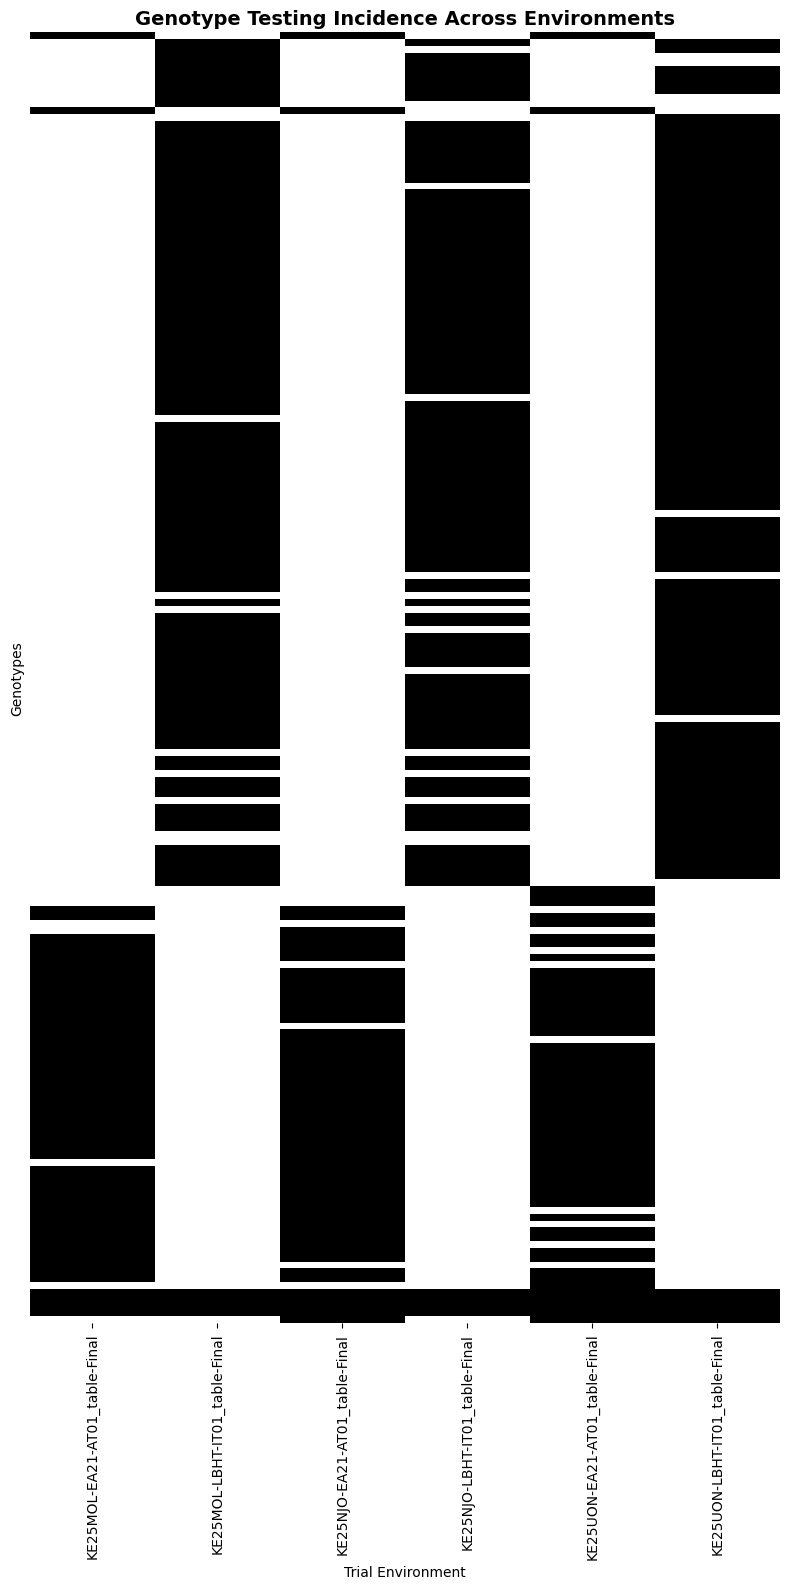

In [14]:
incidence = pd.crosstab(master["geno"], master["trial"])
incidence = (incidence > 0).astype(int)

plt.figure(figsize=(8, 16))
sns.heatmap(incidence, cmap="Greys", cbar=False, yticklabels=False, linewidths=0)
plt.title("Genotype Testing Incidence Across Environments", fontsize=14, fontweight="bold")
plt.xlabel("Trial Environment")
plt.ylabel("Genotypes")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "genotype_environment_incidence.png", dpi=300, bbox_inches="tight")
plt.show()

In [15]:
results_by_trial = {}

for trial_name, df_trial in master.groupby("trial", observed=True):

    df_fit = df_trial.dropna(subset=["weight_g_total"]).copy()
    df_fit["rep"] = df_fit["rep"].astype("category")

    try:
        model = smf.mixedlm(
            "weight_g_total ~ rep",
            data=df_fit,
            groups=df_fit["geno"]
        )
        fit = model.fit(reml=True)
        results_by_trial[trial_name] = fit
        print(f"{trial_name}: converged, {len(df_fit)} obs")
    except Exception as e:
        print(f"{trial_name}: FAILED — {e}")

KE25MOL-EA21-AT01_table-Final: converged, 173 obs
KE25MOL-LBHT-IT01_table-Final: converged, 261 obs
KE25NJO-EA21-AT01_table-Final: converged, 174 obs
KE25NJO-LBHT-IT01_table-Final: converged, 262 obs
KE25UON-EA21-AT01_table-Final: converged, 169 obs
KE25UON-LBHT-IT01_table-Final: converged, 262 obs


Variance components and heritability per trial

In [17]:
var_comp_summary = []

for trial_name, fit in results_by_trial.items():

    var_g = fit.cov_re.iloc[0, 0]
    var_e = fit.scale

    n_rep = master.loc[master["trial"] == trial_name, "rep"].nunique()

    h2 = var_g / (var_g + (var_e / n_rep))

    var_comp_summary.append({
        "Trial": trial_name,
        "Var_G": var_g,
        "Var_E": var_e,
        "N_Rep": n_rep,
        "H2": round(h2, 3)
    })

var_comp_df = pd.DataFrame(var_comp_summary)
var_comp_df

,Trial,Var_G,Var_E,N_Rep,H2
0,KE25MOL-EA21-AT01_table-Final,2.103504e+07,7.067607e+06,1,0.749
1,KE25MOL-LBHT-IT01_table-Final,5.387640e+06,1.482848e+06,1,0.784
2,KE25NJO-EA21-AT01_table-Final,1.033731e+07,2.091693e+07,1,0.331
3,KE25NJO-LBHT-IT01_table-Final,1.099033e+07,4.142512e+06,1,0.726
4,KE25UON-EA21-AT01_table-Final,1.873788e+07,2.062423e+07,1,0.476
5,KE25UON-LBHT-IT01_table-Final,5.423376e+06,2.807750e+06,1,0.659


In [18]:
blup_records = []

for trial_name, fit in results_by_trial.items():
    re = fit.random_effects
    for geno, effect in re.items():
        blup_records.append({
            "Trial": trial_name,
            "geno": geno,
            "BLUP": effect.iloc[0]
        })

blup_df = pd.DataFrame(blup_records)
blup_df["BLUP_kg"] = blup_df["BLUP"] / 1000
blup_df.head()

,Trial,geno,BLUP,BLUP_kg
0,KE25MOL-EA21-AT01_table-Final,CIP312010.759,-345.750261,-0.345750
1,KE25MOL-EA21-AT01_table-Final,CIP312084.731,-3015.001207,-3.015001
2,KE25MOL-EA21-AT01_table-Final,CIP3177023.046,-7039.531152,-7.039531
3,KE25MOL-EA21-AT01_table-Final,CIP3177033.071,-4717.013644,-4.717014
4,KE25MOL-EA21-AT01_table-Final,CIP3187015.677,5318.651686,5.318652


In [19]:
top20_by_trial = (
    blup_df
    .sort_values(["Trial", "BLUP_kg"], ascending=[True, False])
    .groupby("Trial")
    .head(20)
)
top20_by_trial.head(10)

,Trial,geno,BLUP,BLUP_kg
27,KE25MOL-EA21-AT01_table-Final,CIP3217008.098,9573.427981,9.573428
9,KE25MOL-EA21-AT01_table-Final,CIP3217004.022,7954.719099,7.954719
20,KE25MOL-EA21-AT01_table-Final,CIP3217006.021,7768.717458,7.768717
49,KE25MOL-EA21-AT01_table-Final,CIP3217019.001,6874.650586,6.874651
39,KE25MOL-EA21-AT01_table-Final,CIP3217015.071,6044.367162,6.044367
4,KE25MOL-EA21-AT01_table-Final,CIP3187015.677,5318.651686,5.318652
21,KE25MOL-EA21-AT01_table-Final,CIP3217006.028,4976.924255,4.976924
12,KE25MOL-EA21-AT01_table-Final,CIP3217004.058,4911.576378,4.911576
19,KE25MOL-EA21-AT01_table-Final,CIP3217006.008,4587.235080,4.587235
30,KE25MOL-EA21-AT01_table-Final,CIP3217014.002,4464.273157,4.464273


In [20]:
var_comp_df.to_csv(TABLES_DIR / "variance_components_per_trial.csv", index=False)
blup_df.to_csv(TABLES_DIR / "blups_per_trial.csv", index=False)
top20_by_trial.to_csv(TABLES_DIR / "top20_genotypes_per_trial.csv", index=False)

print("Saved: variance_components_per_trial.csv")
print("Saved: blups_per_trial.csv")
print("Saved: top20_genotypes_per_trial.csv")

Saved: variance_components_per_trial.csv
Saved: blups_per_trial.csv
Saved: top20_genotypes_per_trial.csv
